In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATASET_PATH = Path(
    r"D:\Capstone\metal additive manufacturing\data\Original Images and Manual Labels\Original Images and manual labels"
)

PB_PATH = DATASET_PATH / "PB"
OT_PATH = DATASET_PATH / "OT"

PB_LABEL_PATH = DATASET_PATH / "PB_label"
OT_LABEL_PATH = DATASET_PATH / "OT_label"

sns.set_theme(style="whitegrid")

In [8]:
pb_files = list(PB_PATH.glob("*.jpg"))
ot_files = list(OT_PATH.glob("*.jpg"))

pb_stems = {file.stem for file in pb_files}
ot_stems = {file.stem for file in ot_files}

common_stems = pb_stems & ot_stems
pb_only_stems = pb_stems - ot_stems
ot_only_stems = ot_stems - pb_stems

print("Total PB images:", len(pb_stems))
print("Total OT images:", len(ot_stems))
print("Matching filenames:", len(common_stems))
print("PB-only filenames:", len(pb_only_stems))
print("OT-only filenames:", len(ot_only_stems))

Total PB images: 2638
Total OT images: 2674
Matching filenames: 0
PB-only filenames: 2638
OT-only filenames: 2674


In [9]:
print("Matching PB–OT filename examples:")

for filename in sorted(common_stems)[:20]:
    print(filename)

Matching PB–OT filename examples:


In [13]:
pb_xml_stems = {file.stem for file in PB_LABEL_PATH.glob("*.xml")}
ot_xml_stems = {file.stem for file in OT_LABEL_PATH.glob("*.xml")}

alignment_data = []

for stem in sorted(common_stems):
    alignment_data.append({
        "image_stem": stem,
        "pb_image_exists": stem in pb_stems,
        "ot_image_exists": stem in ot_stems,
        "pb_xml_exists": stem in pb_xml_stems,
        "ot_xml_exists": stem in ot_xml_stems
    })

columns = [
    "image_stem",
    "pb_image_exists",
    "ot_image_exists",
    "pb_xml_exists",
    "ot_xml_exists"
]

alignment_df = pd.DataFrame(alignment_data, columns=columns)

print("Matched pairs:", len(alignment_df))

if alignment_df.empty:
    print("No exact filename matches found. We need to inspect naming patterns.")
else:
    print("Pairs with PB XML:", alignment_df["pb_xml_exists"].sum())
    print("Pairs with OT XML:", alignment_df["ot_xml_exists"].sum())
    print(
        "Pairs with both XMLs:",
        (
            alignment_df["pb_xml_exists"] &
            alignment_df["ot_xml_exists"]
        ).sum()
    )

display(alignment_df.head())

Matched pairs: 0
No exact filename matches found. We need to inspect naming patterns.


,image_stem,pb_image_exists,ot_image_exists,pb_xml_exists,ot_xml_exists


In [14]:
print("PB filename examples:")
for file in sorted(pb_files)[:15]:
    print(file.name)

print("\nOT filename examples:")
for file in sorted(ot_files)[:15]:
    print(file.name)

PB filename examples:
SI383820211201123521_00009_20211201T125928.564000.jpg
SI383820211201123521_00010_20211201T125941.618000.jpg
SI383820211201123521_00011_20211201T130024.623000.jpg
SI383820211201123521_00012_20211201T130037.654000.jpg
SI383820211201123521_00013_20211201T130118.809000.jpg
SI383820211201123521_00014_20211201T130131.811000.jpg
SI383820211201123521_00015_20211201T130212.865000.jpg
SI383820211201123521_00016_20211201T130226.929000.jpg
SI383820211201123521_00017_20211201T130306.976000.jpg
SI383820211201123521_00018_20211201T130320.029000.jpg
SI383820211201123521_00019_20211201T130406.431000.jpg
SI383820211201123521_00020_20211201T130419.433000.jpg
SI383820211201123521_00021_20211201T130501.910000.jpg
SI383820211201123521_00022_20211201T130515.036000.jpg
SI383820211201123521_00023_20211201T130554.192000.jpg

OT filename examples:
SI383820211201123521_1000_039_400_Int_32F.jpg
SI383820211201123521_1001_039_440_Int_32F.jpg
SI383820211201123521_1002_039_480_Int_32F.jpg
SI38382

In [15]:
print("PB filename stems:")
print([file.stem for file in sorted(pb_files)[:10]])

print("\nOT filename stems:")
print([file.stem for file in sorted(ot_files)[:10]])

PB filename stems:
['SI383820211201123521_00009_20211201T125928.564000', 'SI383820211201123521_00010_20211201T125941.618000', 'SI383820211201123521_00011_20211201T130024.623000', 'SI383820211201123521_00012_20211201T130037.654000', 'SI383820211201123521_00013_20211201T130118.809000', 'SI383820211201123521_00014_20211201T130131.811000', 'SI383820211201123521_00015_20211201T130212.865000', 'SI383820211201123521_00016_20211201T130226.929000', 'SI383820211201123521_00017_20211201T130306.976000', 'SI383820211201123521_00018_20211201T130320.029000']

OT filename stems:
['SI383820211201123521_1000_039_400_Int_32F', 'SI383820211201123521_1001_039_440_Int_32F', 'SI383820211201123521_1002_039_480_Int_32F', 'SI383820211201123521_1003_039_520_Int_32F', 'SI383820211201123521_1004_039_560_Int_32F', 'SI383820211201123521_1005_039_600_Int_32F', 'SI383820211201123521_1006_039_640_Int_32F', 'SI383820211201123521_1007_039_680_Int_32F', 'SI383820211201123521_1008_039_720_Int_32F', 'SI383820211201123521_10

In [16]:
def get_shared_prefix(filename):
    return filename.split("_")[0]

pb_prefixes = pd.Series(
    [get_shared_prefix(file.stem) for file in pb_files]
).value_counts()

ot_prefixes = pd.Series(
    [get_shared_prefix(file.stem) for file in ot_files]
).value_counts()

print("PB shared prefixes:")
display(pb_prefixes)

print("\nOT shared prefixes:")
display(ot_prefixes)

PB shared prefixes:


SI383820240318120348    1367
SI383820211201123521    1000
SI383820240226095904     271
Name: count, dtype: int64


OT shared prefixes:


SI383820240318120348    1383
SI383820211201123521    1005
SI383820240226095904     286
Name: count, dtype: int64

In [17]:
pb_prefix_set = set(pb_prefixes.index)
ot_prefix_set = set(ot_prefixes.index)

print("Shared identifiers:", pb_prefix_set & ot_prefix_set)
print("PB-only identifiers:", pb_prefix_set - ot_prefix_set)
print("OT-only identifiers:", ot_prefix_set - pb_prefix_set)

Shared identifiers: {'SI383820240318120348', 'SI383820211201123521', 'SI383820240226095904'}
PB-only identifiers: set()
OT-only identifiers: set()


In [18]:
def get_shared_prefix(filename):
    return filename.split("_")[0]

pb_counts = (
    pd.Series([get_shared_prefix(file.stem) for file in pb_files])
    .value_counts()
    .rename("PB_image_count")
)

ot_counts = (
    pd.Series([get_shared_prefix(file.stem) for file in ot_files])
    .value_counts()
    .rename("OT_image_count")
)

build_counts = pd.concat([pb_counts, ot_counts], axis=1).fillna(0).astype(int)

build_counts["difference_OT_minus_PB"] = (
    build_counts["OT_image_count"] - build_counts["PB_image_count"]
)

display(build_counts.sort_index())

,PB_image_count,OT_image_count,difference_OT_minus_PB
SI383820211201123521,1000,1005,5
SI383820240226095904,271,286,15
SI383820240318120348,1367,1383,16


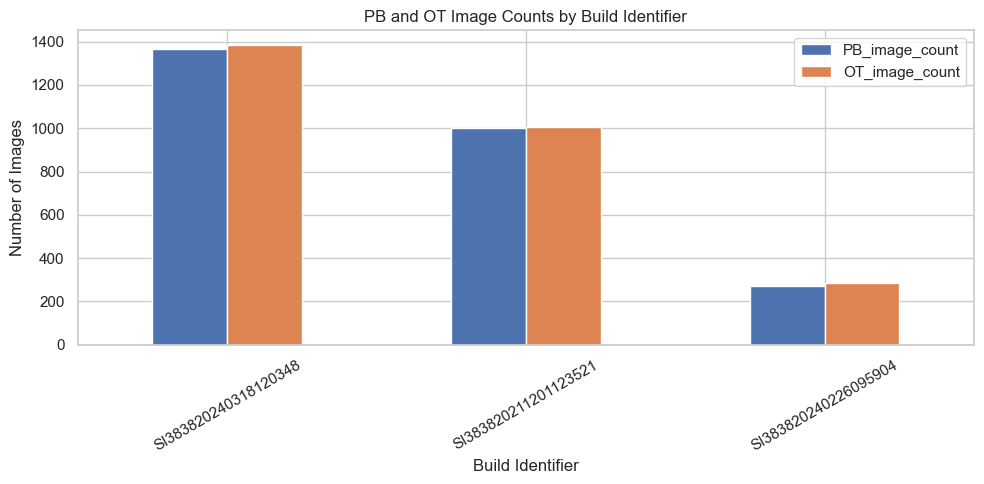

In [19]:
build_counts[["PB_image_count", "OT_image_count"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("PB and OT Image Counts by Build Identifier")
plt.xlabel("Build Identifier")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [20]:
ot_filename_data = []

for file in ot_files:
    parts = file.stem.split("_")

    ot_filename_data.append({
        "filename": file.name,
        "build_id": parts[0],
        "sequence": parts[1] if len(parts) > 1 else None,
        "parameter_1": parts[2] if len(parts) > 2 else None,
        "parameter_2": parts[3] if len(parts) > 3 else None,
        "parameter_3": parts[4] if len(parts) > 4 else None,
        "parameter_4": parts[5] if len(parts) > 5 else None
    })

ot_filename_df = pd.DataFrame(ot_filename_data)

display(ot_filename_df.head(15))

,filename,build_id,sequence,parameter_1,parameter_2,parameter_3,parameter_4
0,SI383820211201123521_1000_039_400_Int_32F.jpg,SI383820211201123521,1000,039,400,Int,32F
1,SI383820211201123521_1001_039_440_Int_32F.jpg,SI383820211201123521,1001,039,440,Int,32F
2,SI383820211201123521_1002_039_480_Int_32F.jpg,SI383820211201123521,1002,039,480,Int,32F
3,SI383820211201123521_1003_039_520_Int_32F.jpg,SI383820211201123521,1003,039,520,Int,32F
4,SI383820211201123521_1004_039_560_Int_32F.jpg,SI383820211201123521,1004,039,560,Int,32F
5,SI383820211201123521_1005_039_600_Int_32F.jpg,SI383820211201123521,1005,039,600,Int,32F
6,SI383820211201123521_1006_039_640_Int_32F.jpg,SI383820211201123521,1006,039,640,Int,32F
7,SI383820211201123521_1007_039_680_Int_32F.jpg,SI383820211201123521,1007,039,680,Int,32F
8,SI383820211201123521_1008_039_720_Int_32F.jpg,SI383820211201123521,1008,039,720,Int,32F
9,SI383820211201123521_1009_039_760_Int_32F.jpg,SI383820211201123521,1009,039,760,Int,32F


In [21]:
for build_id, group in ot_filename_df.groupby("build_id"):
    print("\nBuild:", build_id)

    for column in [
        "parameter_1",
        "parameter_2",
        "parameter_3",
        "parameter_4"
    ]:
        print(column, "unique values:", group[column].nunique())
        print(group[column].value_counts().head(10))


Build: SI383820211201123521
parameter_1 unique values: 41
parameter_1
000    29
039    25
003    25
004    25
005    25
007    25
006    25
008    25
009    25
024    25
Name: count, dtype: int64
parameter_2 unique values: 35
parameter_2
400    40
440    40
480    40
520    40
560    40
600    40
640    40
680    40
720    40
760    40
Name: count, dtype: int64
parameter_3 unique values: 1
parameter_3
Int    1005
Name: count, dtype: int64
parameter_4 unique values: 1
parameter_4
32F    1005
Name: count, dtype: int64

Build: SI383820240226095904
parameter_1 unique values: 6
parameter_1
002    50
003    50
001    50
004    50
000    49
005    37
Name: count, dtype: int64
parameter_2 unique values: 50
parameter_2
020    6
040    6
060    6
080    6
100    6
120    6
140    6
160    6
180    6
200    6
Name: count, dtype: int64
parameter_3 unique values: 1
parameter_3
Int    286
Name: count, dtype: int64
parameter_4 unique values: 1
parameter_4
32F    286
Name: count, dtype: int64

Build:

In [22]:
pb_filename_data = []

for file in pb_files:
    parts = file.stem.split("_")

    pb_filename_data.append({
        "filename": file.name,
        "build_id": parts[0],
        "sequence": parts[1] if len(parts) > 1 else None,
        "timestamp": parts[2] if len(parts) > 2 else None
    })

pb_filename_df = pd.DataFrame(pb_filename_data)

display(pb_filename_df.head(15))

,filename,build_id,sequence,timestamp
0,SI383820211201123521_00009_20211201T125928.564...,SI383820211201123521,00009,20211201T125928.564000
1,SI383820211201123521_00010_20211201T125941.618...,SI383820211201123521,00010,20211201T125941.618000
2,SI383820211201123521_00011_20211201T130024.623...,SI383820211201123521,00011,20211201T130024.623000
3,SI383820211201123521_00012_20211201T130037.654...,SI383820211201123521,00012,20211201T130037.654000
4,SI383820211201123521_00013_20211201T130118.809...,SI383820211201123521,00013,20211201T130118.809000
5,SI383820211201123521_00014_20211201T130131.811...,SI383820211201123521,00014,20211201T130131.811000
6,SI383820211201123521_00015_20211201T130212.865...,SI383820211201123521,00015,20211201T130212.865000
7,SI383820211201123521_00016_20211201T130226.929...,SI383820211201123521,00016,20211201T130226.929000
8,SI383820211201123521_00017_20211201T130306.976...,SI383820211201123521,00017,20211201T130306.976000
9,SI383820211201123521_00018_20211201T130320.029...,SI383820211201123521,00018,20211201T130320.029000


In [23]:
for build_id, group in pb_filename_df.groupby("build_id"):
    print("\nBuild:", build_id)

    sequence = pd.to_numeric(group["sequence"], errors="coerce")
    print("Sequence range:", sequence.min(), "to", sequence.max())

    print("First timestamps:")
    print(group["timestamp"].head(5).tolist())

    print("Last timestamps:")
    print(group["timestamp"].tail(5).tolist())


Build: SI383820211201123521
Sequence range: 9 to 1008
First timestamps:
['20211201T125928.564000', '20211201T125941.618000', '20211201T130024.623000', '20211201T130037.654000', '20211201T130118.809000']
Last timestamps:
['20211202T001356.699000', '20211202T001422.577000', '20211202T001448.951000', '20211202T001513.639000', '20211202T001538.945000']

Build: SI383820240226095904
Sequence range: 9 to 279
First timestamps:
['20240226T103242.617000', '20240226T103404.235000', '20240226T103537.309000', '20240226T103659.671000', '20240226T103830.042000']
Last timestamps:
['20240226T155555.691000', '20240226T155624.555000', '20240226T155652.659000', '20240226T155720.674000', '20240226T155748.576000']

Build: SI383820240318120348
Sequence range: 9 to 1375
First timestamps:
['20240318T123305.455000', '20240318T123330.609000', '20240318T123356.818000', '20240318T123421.934000', '20240318T123447.085000']
Last timestamps:
['20240318T210722.014000', '20240318T210743.818000', '20240318T210805.767000

In [24]:
print("Dataset root:", DATASET_PATH)

for item in DATASET_PATH.iterdir():
    print(item.name, "—", "Folder" if item.is_dir() else "File")

Dataset root: D:\Capstone\metal additive manufacturing\data\Original Images and Manual Labels\Original Images and manual labels
OT — Folder
OT_label — Folder
PB — Folder
PB_label — Folder


In [25]:
metadata_extensions = [
    ".csv", ".xlsx", ".xls", ".json", ".txt",
    ".yaml", ".yml", ".log", ".xml"
]

metadata_files = []

for file in DATASET_PATH.rglob("*"):
    if file.is_file() and file.suffix.lower() in metadata_extensions:
        # Exclude the annotation XML files themselves
        if file.parent not in [PB_LABEL_PATH, OT_LABEL_PATH]:
            metadata_files.append(file)

print("Potential metadata files:", len(metadata_files))

for file in metadata_files[:100]:
    print(file.relative_to(DATASET_PATH))

Potential metadata files: 0


In [28]:
import xml.etree.ElementTree as ET

def inspect_xml_fields(xml_path):
    root = ET.parse(xml_path).getroot()

    print(f"\nFile: {xml_path.name}")
    print("Top-level fields:")

    for child in root:
        if child.tag == "object":
            print("object: annotation")
        else:
            text = child.text.strip() if child.text else ""
            print(f"{child.tag}: {text}")

        if child.tag == "object":
            print("Object fields:")
            for obj_child in child:
                if obj_child.tag == "bndbox":
                    print("  bndbox:")
                    for coord in obj_child:
                        print(f"    {coord.tag}: {coord.text}")
                else:
                    print(f"  {obj_child.tag}: {obj_child.text}")

            break


sample_pb_xml = next(PB_LABEL_PATH.glob("*.xml"))
sample_ot_xml = next(OT_LABEL_PATH.glob("*.xml"))

inspect_xml_fields(sample_pb_xml)
inspect_xml_fields(sample_ot_xml)


File: SI383820211201123521_00009_20211201T125928.564000.xml
Top-level fields:
folder: Powder_bed
filename: SI383820211201123521_00009_20211201T125928.564000.jpg
path: C:\Users\Xinyi YIN\OneDrive - Aalto University\data\Data\Powder_bed\SI383820211201123521_00009_20211201T125928.564000.jpg
source: 
size: 
segmented: 0
object: annotation
Object fields:
  name: defects
  pose: Unspecified
  truncated: 0
  difficult: 0
  bndbox:
    xmin: 276
    ymin: 725
    xmax: 350
    ymax: 738

File: SI383820211201123521_113_003_920_Int_32F.xml
Top-level fields:
folder: OT
filename: SI383820211201123521_113_003_920_Int_32F.jpg
path: C:\Users\Xinyi YIN\OneDrive - Aalto University\data\Data\OT\SI383820211201123521_113_003_920_Int_32F.jpg
source: 
size: 
segmented: 0
object: annotation
Object fields:
  name: overheated
  pose: Unspecified
  truncated: 0
  difficult: 0
  bndbox:
    xmin: 391
    ymin: 1159
    xmax: 447
    ymax: 1210


In [22]:
from pathlib import Path
OUTPUT_PATH = Path("outputs")
OUTPUT_PATH.mkdir(exist_ok=True)

pb_filename_df.to_csv(OUTPUT_PATH / "pb_filename_metadata.csv", index=False)
ot_filename_df.to_csv(OUTPUT_PATH / "ot_filename_metadata.csv", index=False)
build_counts.to_csv(OUTPUT_PATH / "pb_ot_build_counts.csv")
alignment_df.to_csv(OUTPUT_PATH / "pb_ot_exact_filename_matches.csv", index=False)

print("Alignment analysis tables saved to:", OUTPUT_PATH.resolve())

Alignment analysis tables saved to: D:\Capstone\metal additive manufacturing\EDA\outputs
